# Customer Churn Prediction & Retention Platform
### Notebook 01: Load, Clean, Explore (EDA) and Prepare the Data

**Business problem:** A telecom company is losing customers. When a customer cancels the service, that is called **churn**.
We want to predict **which customers are likely to leave**, so the company can act early (discounts, tech support, contract offers). That is the **retention** part.

**ML problem type:** Binary classification. Target `Churn` = 1 (left) / 0 (stayed).

**Dataset:** IBM Telco Customer Churn (Kaggle): 7,043 customers, 21 columns.

This notebook covers Lessons 1 to 4. No models are trained here (that starts in Lesson 5).

# Lesson 1: Load the data and take a first look

**Imports.** We load the four libraries we need:
- `pandas`: tables (DataFrames), the main tool for working with data
- `numpy`: fast math on numbers
- `matplotlib` / `seaborn`: charts (seaborn is built on top of matplotlib and makes nicer plots with less code)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Load the CSV file** into a DataFrame called `df`.
The path `../data/` means "go up one folder from `notebooks/`, then into `data/`".

In [2]:
df = pd.read_csv("../data/telco_dataset.csv")

**Look at the first 5 rows** to get a feel for what each column contains. Each row is one customer.

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Check the size**: (rows, columns). We expect **(7043, 21)**: 7,043 customers and 21 columns.

In [4]:
df.shape

(7043, 21)

**`df.info()`** shows every column's name, how many non-missing values it has, and its data type (`int64`, `float64`, `object` = text).
This is the quickest way to spot columns stored with the wrong type.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In the output above, the `TotalCharges` column should be a number (`float`), but its dtype is `object` (text). Something is not okay.
Some values are probably not valid numbers (for example, blank spaces). We will fix this in Lesson 2.

**How many customers churned?**
- `value_counts()` gives the raw counts of Yes / No.
- `value_counts(normalize=True) * 100` gives the same thing as percentages.

In [6]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


**Bar chart of churn counts** to see the class balance at a glance.

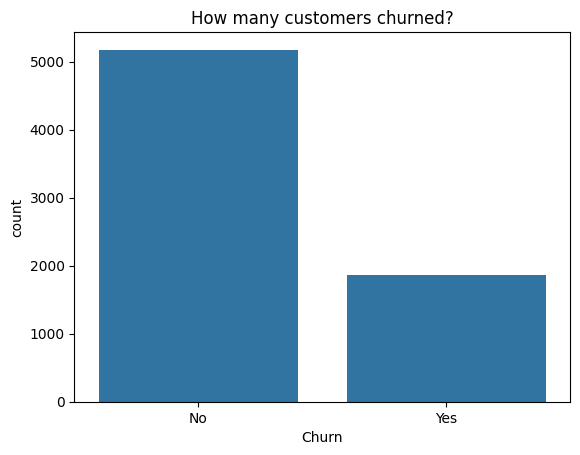

In [7]:
sns.countplot(x="Churn", data=df)
plt.title("How many customers churned?")
plt.show()

## Findings (Lesson 1)
- The dataset has 7,043 customers and 21 columns. Each row is one customer, and `Churn` is the target (Yes = left, No = stayed).
- Churn: No = 5,174 (about 73.5%), Yes = 1,869 (about 26.5%). The data is **imbalanced** (fewer people left than stayed), so **accuracy alone will be misleading** later.
  (A model that always says "No" would already be 73.5% accurate and completely useless.)
- `TotalCharges` is stored as text but should be a number, so it needs cleaning.

# Lesson 2: Data Cleaning

**Convert `TotalCharges` from text to numbers.**
`pd.to_numeric` turns text like `"29.85"` into the number `29.85`.
`errors="coerce"` means: if a value cannot be converted (such as a blank `" "`), put `NaN` (missing) instead of crashing.

In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

**How many values became missing, and who are these customers?**
Before fixing missing values, we **investigate** them. We print the count and show those rows next to `tenure` (months with the company) and `MonthlyCharges`.

In [9]:
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


All 11 missing rows have **tenure = 0**: brand-new customers who have not been billed yet.
So their total charges really are **0**. Filling with 0 is the logically correct value. (Dropping these 11 rows would also be acceptable, since they are only 0.16% of the data.)

In [10]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

**Check for missing values in every column.** Every count should now be 0.

In [11]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

**Check for duplicate rows.** `df.duplicated().sum()` counts rows that are exact copies of an earlier row. We expect 0.
(We check this *before* dropping `customerID`, because every customer has a unique ID.)

In [12]:
df.duplicated().sum()

np.int64(0)

**Drop `customerID`.** An ID is just a random label with no real pattern. If we keep it, a model could learn fake patterns from it.
`axis=1` means "drop a column" (`axis=0` would mean rows). Expected shape: **(7043, 20)**.

In [13]:
df = df.drop("customerID", axis=1)
df.shape

(7043, 20)

**Look at the unique values of every text (object) column.** This tells us which categories exist, so we know how to encode them later.

In [14]:
for col in df.select_dtypes(include="object").columns:
    print(col, "→", df[col].unique())

gender → ['Female' 'Male']
Partner → ['Yes' 'No']
Dependents → ['No' 'Yes']
PhoneService → ['No' 'Yes']
MultipleLines → ['No phone service' 'No' 'Yes']
InternetService → ['DSL' 'Fiber optic' 'No']
OnlineSecurity → ['No' 'Yes' 'No internet service']
OnlineBackup → ['Yes' 'No' 'No internet service']
DeviceProtection → ['No' 'Yes' 'No internet service']
TechSupport → ['No' 'Yes' 'No internet service']
StreamingTV → ['No' 'Yes' 'No internet service']
StreamingMovies → ['No' 'Yes' 'No internet service']
Contract → ['Month-to-month' 'One year' 'Two year']
PaperlessBilling → ['Yes' 'No']
PaymentMethod → ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn → ['No' 'Yes']


Notice the extra categories **"No internet service"** and **"No phone service"** in the service columns.
They only repeat what `InternetService` / `PhoneService` already tell us. We will handle this during encoding (Lesson 4).

**Convert the target `Churn` to numbers:** Yes becomes 1, No becomes 0. Models need numbers, and this also lets us calculate churn rates by taking the mean (Lesson 3).

> **Warning:** Run this cell **only once**. After the first run, `Churn` already contains 1/0, so a second run finds no "Yes"/"No" to map and turns every value into `NaN`.
> If that happens, use **Run All** (or Restart Kernel + Run All) to start fresh from the CSV.

In [15]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

**Final check after cleaning:** 20 columns, 7,043 non-null values in each, `TotalCharges` is `float64` and `Churn` is `int64`.

In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


## Findings (Lesson 2)
- Converted `TotalCharges` from text to numbers and found 11 missing values. All were new customers (tenure = 0), so I filled them with 0.
- No duplicates and no other missing values.
- Dropped `customerID` because it carries no predictive information.
- Converted `Churn` to 1 (left) / 0 (stayed).
- Several service columns have a "No internet service" / "No phone service" category; I'll handle these during encoding.

# Lesson 3: Exploratory Data Analysis (EDA)

**Key idea:** `Churn` is now 0/1. The **mean** of a 0/1 column is the share of 1s.
So **the mean of Churn within a group = that group's churn rate**.

Example: if a group has 10 customers and 4 of them churned, the mean is (1+1+1+1+0+0+0+0+0+0) / 10 = 0.4, which is a 40% churn rate.

**Churn rate by contract type.**
`groupby("Contract")` splits customers into groups by contract, `["Churn"].mean()` gives each group's churn rate, and `* 100` turns it into a percentage.

In [17]:
df.groupby("Contract")["Churn"].mean() * 100

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

**A helper function** so we don't repeat the same code for every column.
`churn_rate(col)`:
1. calculates the churn rate (%) for each category in `col`
2. sorts it from highest to lowest
3. prints the numbers (rounded to 1 decimal place)
4. draws a bar chart

In [18]:
def churn_rate(col):
    rate = df.groupby(col)["Churn"].mean() * 100
    rate = rate.sort_values(ascending=False)
    print(rate.round(1))
    rate.plot(kind="bar", color="steelblue")
    plt.title(f"Churn rate by {col}")
    plt.ylabel("Churn rate (%)")
    plt.xticks(rotation=30, ha="right")
    plt.show()

**Internet and support services:** does the type of internet, or having tech support / online security, change churn?

InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: Churn, dtype: float64


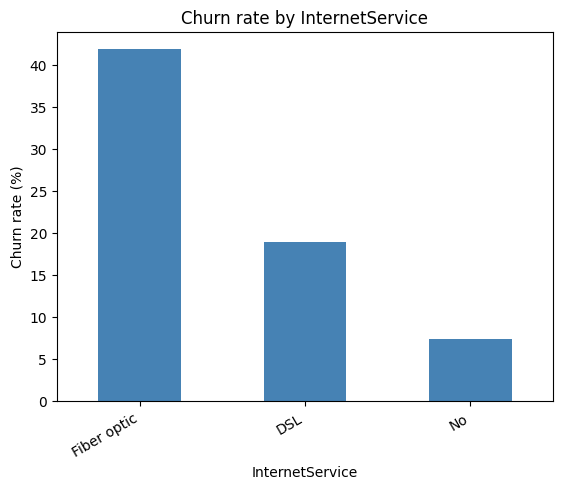

TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: Churn, dtype: float64


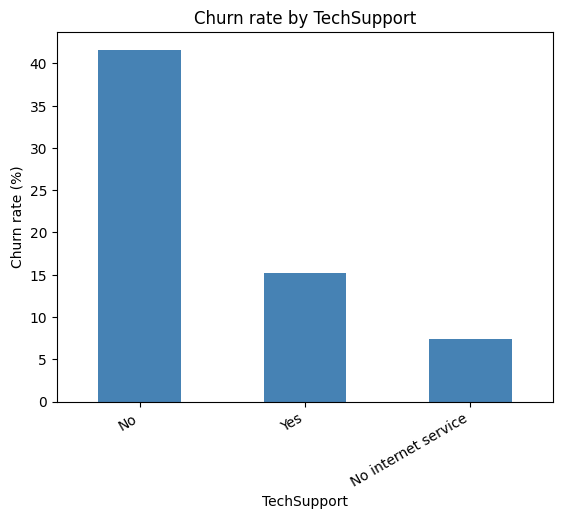

OnlineSecurity
No                     41.8
Yes                    14.6
No internet service     7.4
Name: Churn, dtype: float64


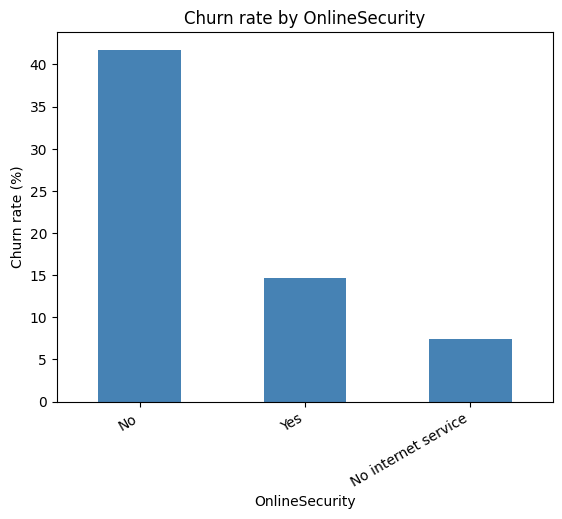

In [19]:
churn_rate("InternetService")
churn_rate("TechSupport")
churn_rate("OnlineSecurity")

**Billing:** does the way a customer pays, or paperless billing, change churn?

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: Churn, dtype: float64


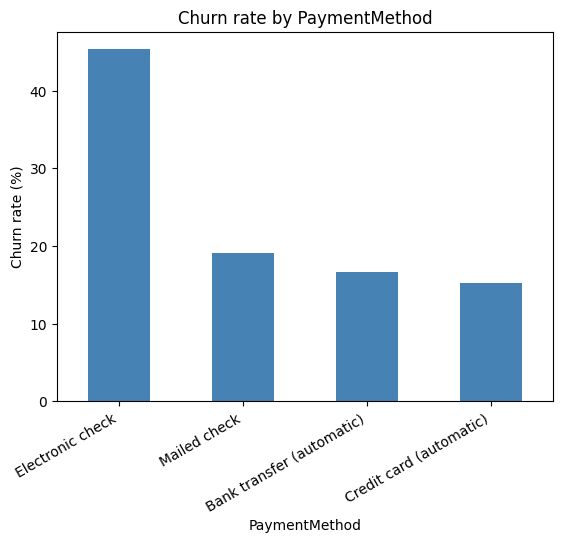

PaperlessBilling
Yes    33.6
No     16.3
Name: Churn, dtype: float64


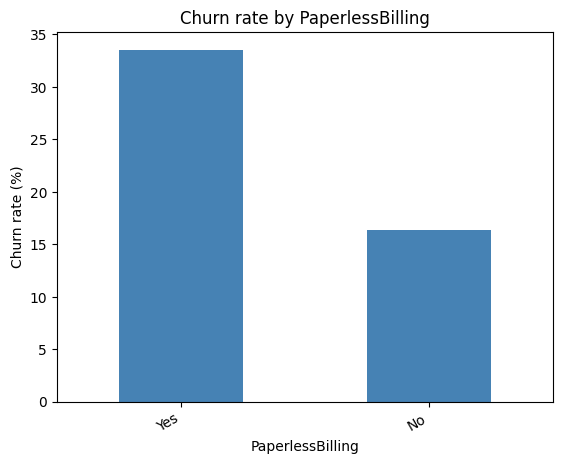

In [20]:
churn_rate("PaymentMethod")
churn_rate("PaperlessBilling")

**Demographics:** do age, partner, dependents or gender change churn?

SeniorCitizen
1    41.7
0    23.6
Name: Churn, dtype: float64


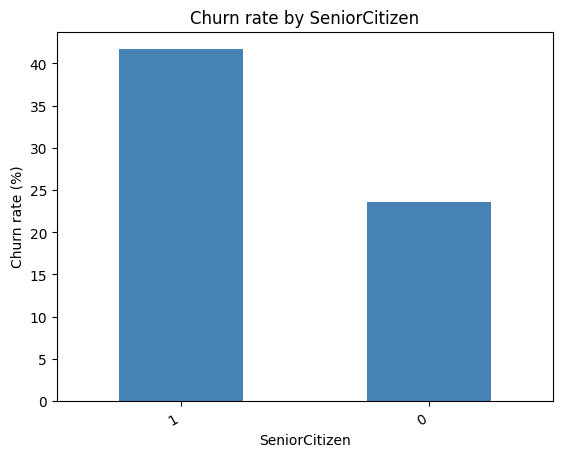

Partner
No     33.0
Yes    19.7
Name: Churn, dtype: float64


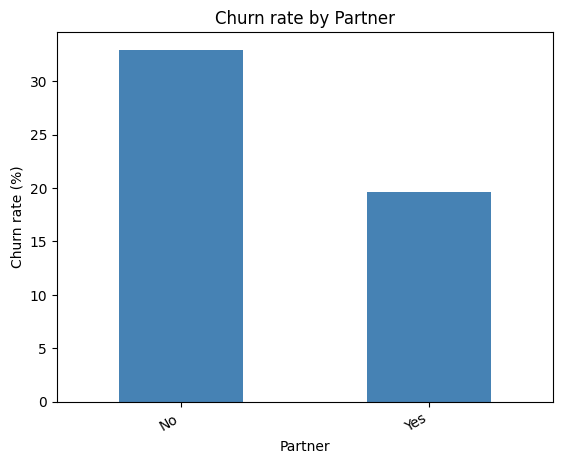

Dependents
No     31.3
Yes    15.5
Name: Churn, dtype: float64


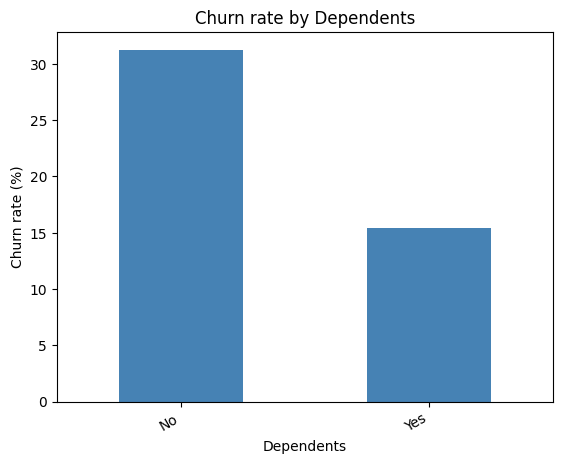

gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64


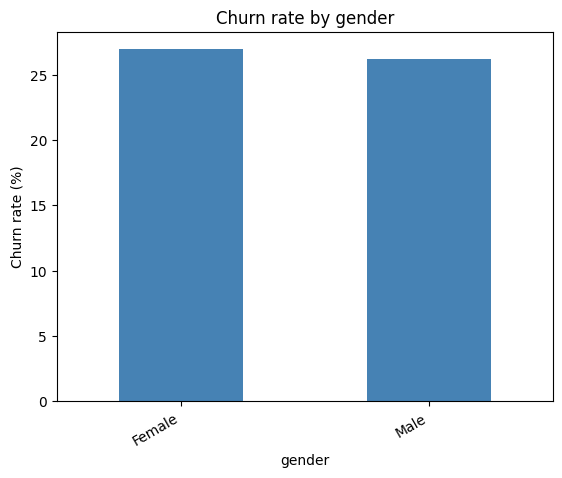

In [21]:
churn_rate("SeniorCitizen")
churn_rate("Partner")
churn_rate("Dependents")
churn_rate("gender")

**Numeric columns: compare the typical (median) customer who stayed vs. churned.**
We use the **median** (middle value) instead of the mean because it is not pulled up or down by a few extreme values.

In [22]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median()

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.425,1679.525
1,10.0,79.650,703.550


**Histogram of tenure, coloured by churn.**
`bins=30` splits tenure into 30 bars, `hue="Churn"` colours each bar by churn, and `multiple="stack"` stacks the two colours.
This shows *when* in the customer's life churn happens.

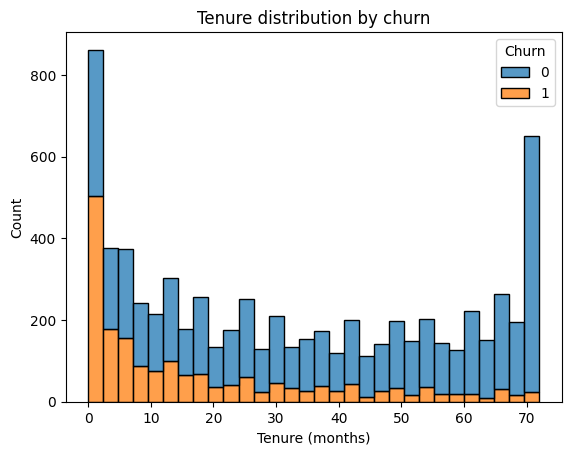

In [23]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Tenure distribution by churn")
plt.xlabel("Tenure (months)")
plt.show()

**Boxplot of monthly charges for stayed (0) vs. churned (1).**
The box shows the middle 50% of customers, and the line inside the box is the median.

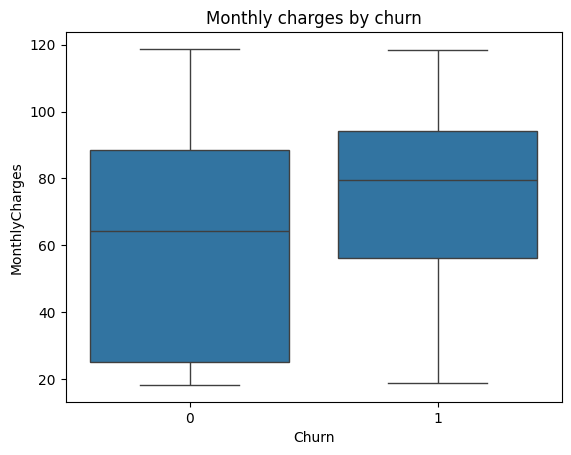

In [24]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly charges by churn")
plt.show()

**Correlation heatmap.** Correlation goes from -1 to +1:
- **+1**: when one goes up, the other goes up
- **-1**: when one goes up, the other goes down
- **0**: no linear relationship

`annot=True` writes the numbers on the squares, `fmt=".2f"` shows 2 decimals, and `cmap="coolwarm"` uses red for positive and blue for negative.

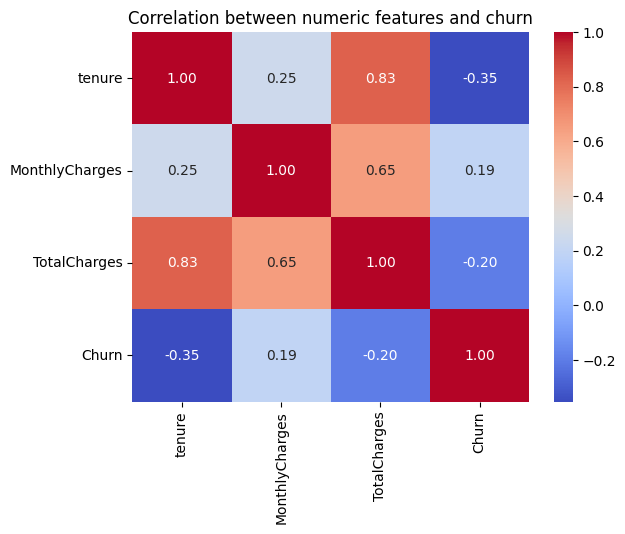

In [25]:
corr = df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between numeric features and churn")
plt.show()

## Findings (Lesson 3)
1. **Contract is the strongest factor:** month-to-month about 43% churn vs. two-year about 3%.
2. **New customers churn the most.** Median tenure is about 10 months for churned customers vs. about 38 for those who stayed, so the first months are the danger zone.
3. **Fiber optic customers churn the most** (about 42%), vs. DSL about 19% and no internet about 7%.
4. **No TechSupport / no OnlineSecurity means about 3 times higher churn** (about 42% vs. about 15%).
5. **Electronic check payers churn the most** (about 45%). Automatic payments (bank transfer / credit card) are about 15 to 17%.
6. **Seniors** (about 42% vs. about 24%) and customers **without a partner/dependents** churn more.
7. **Gender has no effect** (Female about 26.9% vs. Male about 26.2%).
8. **tenure and TotalCharges are highly correlated (0.83)** because TotalCharges is roughly tenure times MonthlyCharges. Churned customers also pay more per month (median about $80 vs. about $64).

**Business ideas:** push long-term contracts, offer free tech support to new fiber customers, and encourage autopay.

# Lesson 4: Data Preparation

Models only understand numbers, so we need to:
- **A.** Encode text columns as numbers
- **B.** Split the data into a training set and a test set
- **C.** Scale the numeric columns

## Part A: Encoding

**Make a copy for modelling.** We keep `df` readable (with "Yes"/"No" text) for EDA, and do all encoding on `df_model`.
`.copy()` makes a real, independent copy, so changing `df_model` does not change `df`.

In [26]:
df_model = df.copy()

**Replace "No internet service" and "No phone service" with "No".**
If a customer has no internet, they obviously have no online security. That information already exists in `InternetService` / `PhoneService`, so repeating it adds nothing.
After this, each of these columns has only Yes / No.

In [27]:
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]

for col in service_cols:
    df_model[col] = df_model[col].replace({"No internet service": "No",
                                           "No phone service": "No"})
    print(col, "→", df_model[col].unique())

MultipleLines → ['No' 'Yes']
OnlineSecurity → ['No' 'Yes']
OnlineBackup → ['Yes' 'No']
DeviceProtection → ['No' 'Yes']
TechSupport → ['No' 'Yes']
StreamingTV → ['No' 'Yes']
StreamingMovies → ['No' 'Yes']


**Binary encoding.** Columns with only two values become 1/0: Yes becomes 1, No becomes 0.
For `gender`: Male becomes 1, Female becomes 0 (the choice of which is 1 doesn't matter; it's just a label).

In [28]:
binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"] + service_cols

for col in binary_cols:
    df_model[col] = df_model[col].map({"Yes": 1, "No": 0})

df_model["gender"] = df_model["gender"].map({"Male": 1, "Female": 0})

df_model.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1


**One-hot encoding** for columns with 3+ categories that have **no natural order**: `InternetService`, `Contract`, `PaymentMethod`.

- **Why not label encoding (0, 1, 2)?** It would create a false order. For example, DSL=0, Fiber=1, No=2 makes the model think "No internet" is "bigger" than Fiber.
- **One-hot encoding** creates a separate 0/1 column for each category instead.
- **`drop_first=True`** removes one column per group because it is redundant: if a customer is not "One year" and not "Two year", they must be "Month-to-month".
- **`dtype=int`** gives 0/1 instead of True/False.

In [29]:
df_model = pd.get_dummies(df_model,
                          columns=["InternetService", "Contract", "PaymentMethod"],
                          drop_first=True, dtype=int)

df_model.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,...,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,...,29.85,29.85,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,...,56.95,1889.50,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,...,42.30,1840.75,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,...,70.70,151.65,1,1,0,0,0,0,1,0


**Checks after encoding:**
- shape should be **(7043, 24)**
- total missing values should be **0** (a typo in a `map` would create NaNs)
- there should be **no `object` (text) columns left**

In [30]:
print("Shape:", df_model.shape)
print("Total missing values:", df_model.isnull().sum().sum())
print("Object columns left:", list(df_model.select_dtypes(include="object").columns))
print()
print(df_model.dtypes)

Shape: (7043, 24)
Total missing values: 0
Object columns left: []

gender                                     int64
SeniorCitizen                              int64
Partner                                    int64
Dependents                                 int64
tenure                                     int64
PhoneService                               int64
MultipleLines                              int64
OnlineSecurity                             int64
OnlineBackup                               int64
DeviceProtection                           int64
TechSupport                                int64
StreamingTV                                int64
StreamingMovies                            int64
PaperlessBilling                           int64
MonthlyCharges                           float64
TotalCharges                             float64
Churn                                      int64
InternetService_Fiber optic                int64
InternetService_No                         int64
Co

**Save the clean, encoded data** to `data/telco_clean.csv` so later lessons can load it directly.
`index=False` stops pandas from writing the row numbers as an extra column.

In [31]:
df_model.to_csv("../data/telco_clean.csv", index=False)

## Part B: Train/test split

**Split the data into training (80%) and test (20%) sets.**
- `X` = the features (everything except Churn), `y` = the target (Churn).
- The **training set** is what the model learns from. The **test set** is the "real exam" on customers the model has never seen.
- `test_size=0.2`: 20% goes to the test set.
- `stratify=y` keeps the churn ratio (about 26.5%) the **same** in both sets.
- `random_state=42` makes the split repeatable, so we get the same split every time we run it.

In [32]:
from sklearn.model_selection import train_test_split

X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

**Check the split:** expected X_train **(5634, 23)**, X_test **(1409, 23)**, and churn about 26.5% in both.

In [33]:
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("Churn % in train:", round(y_train.mean() * 100, 2))
print("Churn % in test: ", round(y_test.mean() * 100, 2))

X_train: (5634, 23)
X_test:  (1409, 23)
Churn % in train: 26.54
Churn % in test:  26.54


## Part C: Scaling

**Standardize the 3 numeric columns** (`tenure`, `MonthlyCharges`, `TotalCharges`).
They are on very different scales (tenure 0 to 72, TotalCharges up to about 8,700). `StandardScaler` converts each to **mean 0, standard deviation 1**, so no column dominates just because its numbers are bigger.

**Important: avoid data leakage.**
- `fit_transform` on **train**: learn the mean/std from training data only, then scale it.
- `transform` on **test**: reuse the *training* mean/std. We never let the test set "teach" the scaler; otherwise information from the exam leaks into training.

We scale copies (`X_train_scaled`, `X_test_scaled`). Scaled data is for **Logistic Regression** (Lesson 5); tree models later will use the unscaled `X_train`.

In [34]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

**Check the scaling:** on the training set, mean should be about 0 and std about 1 for each numeric column.

In [35]:
X_train_scaled[num_cols].describe().round(3)

,tenure,MonthlyCharges,TotalCharges
count,5634.000,5634.000,5634.000
mean,-0.000,-0.000,0.000
std,1.000,1.000,1.000
min,-1.322,-1.544,-1.009
25%,-0.956,-0.971,-0.832
50%,-0.142,0.185,-0.397
75%,0.916,0.832,0.674
max,1.608,1.786,2.802


## Findings (Lesson 4)
1. Simplified "No internet service" / "No phone service" to "No".
2. Binary encoding for Yes/No columns; one-hot encoding for `InternetService`, `Contract` and `PaymentMethod` (`drop_first=True`), giving **23 features** plus Churn = 24 columns.
3. 80/20 stratified split: 5,634 train / 1,409 test, churn about 26.5% in both.
4. StandardScaler on the 3 numeric columns, **fitted on train only** to avoid leakage.
5. Saved the encoded data to `data/telco_clean.csv`.